In [ ]:
## Importing the Dependencies
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score


In [62]:
##Loading the dataset to a pandas dataframe
from google.colab import files
# Upload sonar.csv from your desktop
uploaded = files.upload()
# Load into pandas
data = pd.read_csv("sonar.csv", header=None)
print(data.shape)   # should be (208, 61)
print(data.head())


Saving sonar.csv to sonar (1).csv
(208, 61)
       0       1       2       3       4       5       6       7       8   \
0  0.0200  0.0371  0.0428  0.0207  0.0954  0.0986  0.1539  0.1601  0.3109   
1  0.0453  0.0523  0.0843  0.0689  0.1183  0.2583  0.2156  0.3481  0.3337   
2  0.0262  0.0582  0.1099  0.1083  0.0974  0.2280  0.2431  0.3771  0.5598   
3  0.0100  0.0171  0.0623  0.0205  0.0205  0.0368  0.1098  0.1276  0.0598   
4  0.0762  0.0666  0.0481  0.0394  0.0590  0.0649  0.1209  0.2467  0.3564   

       9   ...      51      52      53      54      55      56      57  \
0  0.2111  ...  0.0027  0.0065  0.0159  0.0072  0.0167  0.0180  0.0084   
1  0.2872  ...  0.0084  0.0089  0.0048  0.0094  0.0191  0.0140  0.0049   
2  0.6194  ...  0.0232  0.0166  0.0095  0.0180  0.0244  0.0316  0.0164   
3  0.1264  ...  0.0121  0.0036  0.0150  0.0085  0.0073  0.0050  0.0044   
4  0.4459  ...  0.0031  0.0054  0.0105  0.0110  0.0015  0.0072  0.0048   

       58      59  60  
0  0.0090  0.0032   R  


In [63]:
# number of rows and columns
data.shape

(208, 61)

In [64]:
data.describe()  ##Statistical measures for the data

,0,1,2,3,4,5,6,7,8,9,...,50,51,52,53,54,55,56,57,58,59
count,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,...,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000
mean,0.029164,0.038437,0.043832,0.053892,0.075202,0.104570,0.121747,0.134799,0.178003,0.208259,...,0.016069,0.013420,0.010709,0.010941,0.009290,0.008222,0.007820,0.007949,0.007941,0.006507
std,0.022991,0.032960,0.038428,0.046528,0.055552,0.059105,0.061788,0.085152,0.118387,0.134416,...,0.012008,0.009634,0.007060,0.007301,0.007088,0.005736,0.005785,0.006470,0.006181,0.005031
min,0.001500,0.000600,0.001500,0.005800,0.006700,0.010200,0.003300,0.005500,0.007500,0.011300,...,0.000000,0.000800,0.000500,0.001000,0.000600,0.000400,0.000300,0.000300,0.000100,0.000600
25%,0.013350,0.016450,0.018950,0.024375,0.038050,0.067025,0.080900,0.080425,0.097025,0.111275,...,0.008425,0.007275,0.005075,0.005375,0.004150,0.004400,0.003700,0.003600,0.003675,0.003100
50%,0.022800,0.030800,0.034300,0.044050,0.062500,0.092150,0.106950,0.112100,0.152250,0.182400,...,0.013900,0.011400,0.009550,0.009300,0.007500,0.006850,0.005950,0.005800,0.006400,0.005300
75%,0.035550,0.047950,0.057950,0.064500,0.100275,0.134125,0.154000,0.169600,0.233425,0.268700,...,0.020825,0.016725,0.014900,0.014500,0.012100,0.010575,0.010425,0.010350,0.010325,0.008525
max,0.137100,0.233900,0.305900,0.426400,0.401000,0.382300,0.372900,0.459000,0.682800,0.710600,...,0.100400,0.070900,0.039000,0.035200,0.044700,0.039400,0.035500,0.044000,0.036400,0.043900


In [65]:
data[60].value_counts()

,count
60,
M,111
R,97


In [66]:
data.groupby(60).mean()

,0,1,2,3,4,5,6,7,8,9,...,50,51,52,53,54,55,56,57,58,59
60,,,,,,,,,,,,,,,,,,,,,
M,0.034989,0.045544,0.050720,0.064768,0.086715,0.111864,0.128359,0.149832,0.213492,0.251022,...,0.019352,0.016014,0.011643,0.012185,0.009923,0.008914,0.007825,0.009060,0.008695,0.006930
R,0.022498,0.030303,0.035951,0.041447,0.062028,0.096224,0.114180,0.117596,0.137392,0.159325,...,0.012311,0.010453,0.009640,0.009518,0.008567,0.007430,0.007814,0.006677,0.007078,0.006024


In [67]:
# seperating data and labels
x=data.drop(columns =60, axis=1)
y=data[60]
print(x)
print(y)

         0       1       2       3       4       5       6       7       8   \
0    0.0200  0.0371  0.0428  0.0207  0.0954  0.0986  0.1539  0.1601  0.3109   
1    0.0453  0.0523  0.0843  0.0689  0.1183  0.2583  0.2156  0.3481  0.3337   
2    0.0262  0.0582  0.1099  0.1083  0.0974  0.2280  0.2431  0.3771  0.5598   
3    0.0100  0.0171  0.0623  0.0205  0.0205  0.0368  0.1098  0.1276  0.0598   
4    0.0762  0.0666  0.0481  0.0394  0.0590  0.0649  0.1209  0.2467  0.3564   
..      ...     ...     ...     ...     ...     ...     ...     ...     ...   
203  0.0187  0.0346  0.0168  0.0177  0.0393  0.1630  0.2028  0.1694  0.2328   
204  0.0323  0.0101  0.0298  0.0564  0.0760  0.0958  0.0990  0.1018  0.1030   
205  0.0522  0.0437  0.0180  0.0292  0.0351  0.1171  0.1257  0.1178  0.1258   
206  0.0303  0.0353  0.0490  0.0608  0.0167  0.1354  0.1465  0.1123  0.1945   
207  0.0260  0.0363  0.0136  0.0272  0.0214  0.0338  0.0655  0.1400  0.1843   

         9   ...      50      51      52      53   

In [68]:
# training and test data
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,stratify=y,random_state=1)

In [69]:
print(x.shape , y_train.shape , x_test.shape)
print(x_train)
print(y_train)

(208, 60) (166,) (42, 60)
         0       1       2       3       4       5       6       7       8   \
183  0.0096  0.0404  0.0682  0.0688  0.0887  0.0932  0.0955  0.2140  0.2546   
27   0.0177  0.0300  0.0288  0.0394  0.0630  0.0526  0.0688  0.0633  0.0624   
149  0.0207  0.0535  0.0334  0.0818  0.0740  0.0324  0.0918  0.1070  0.1553   
4    0.0762  0.0666  0.0481  0.0394  0.0590  0.0649  0.1209  0.2467  0.3564   
94   0.0025  0.0309  0.0171  0.0228  0.0434  0.1224  0.1947  0.1661  0.1368   
..      ...     ...     ...     ...     ...     ...     ...     ...     ...   
0    0.0200  0.0371  0.0428  0.0207  0.0954  0.0986  0.1539  0.1601  0.3109   
140  0.0412  0.1135  0.0518  0.0232  0.0646  0.1124  0.1787  0.2407  0.2682   
154  0.0117  0.0069  0.0279  0.0583  0.0915  0.1267  0.1577  0.1927  0.2361   
131  0.1150  0.1163  0.0866  0.0358  0.0232  0.1267  0.2417  0.2661  0.4346   
203  0.0187  0.0346  0.0168  0.0177  0.0393  0.1630  0.2028  0.1694  0.2328   

         9   ...      50 

In [70]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.model_selection import cross_val_score

In [71]:
# Creating the machine learning models

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=1
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=1
    )
}

print("Models created successfully.")

Models created successfully.


In [72]:
# Training all four models

for name, model in models.items():
    model.fit(x_train, y_train)
    print(name, "trained successfully")

Logistic Regression trained successfully
KNN trained successfully
Decision Tree trained successfully
Random Forest trained successfully


In [73]:
# Evaluating all four models on the test data

results = []

for name, model in models.items():
    y_pred = model.predict(x_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, pos_label="M")
    recall = recall_score(y_test, y_pred, pos_label="M")
    f1 = f1_score(y_test, y_pred, pos_label="M")

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.666667,0.722222,0.590909,0.650000
1,KNN,0.809524,0.769231,0.909091,0.833333
2,Decision Tree,0.785714,0.882353,0.681818,0.769231
3,Random Forest,0.809524,0.791667,0.863636,0.826087


In [74]:
# Comparing training and test accuracy

for name, model in models.items():
    train_pred = model.predict(x_train)
    test_pred = model.predict(x_test)

    train_accuracy = accuracy_score(y_train, train_pred)
    test_accuracy = accuracy_score(y_test, test_pred)

    print(name)
    print("Training Accuracy:", train_accuracy)
    print("Test Accuracy:", test_accuracy)
    print()

Logistic Regression
Training Accuracy: 0.9518072289156626
Test Accuracy: 0.6666666666666666

KNN
Training Accuracy: 0.8795180722891566
Test Accuracy: 0.8095238095238095

Decision Tree
Training Accuracy: 1.0
Test Accuracy: 0.7857142857142857

Random Forest
Training Accuracy: 1.0
Test Accuracy: 0.8095238095238095



In [75]:
# 5-Fold Cross-Validation

cv_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        x,
        y,
        cv=5,
        scoring="accuracy"
    )

    cv_results.append({
        "Model": name,
        "CV Mean Accuracy": scores.mean(),
        "CV Standard Deviation": scores.std()
    })

    print("=" * 50)
    print(name)
    print("Fold Accuracies:", scores)
    print("Mean Accuracy:", scores.mean())
    print("Standard Deviation:", scores.std())

Logistic Regression
Fold Accuracies: [0.4047619  0.69047619 0.73809524 0.75609756 0.58536585]
Mean Accuracy: 0.634959349593496
Standard Deviation: 0.12949438275194813
KNN
Fold Accuracies: [0.5952381  0.64285714 0.57142857 0.73170732 0.24390244]
Mean Accuracy: 0.5570267131242741
Standard Deviation: 0.16588822160739738
Decision Tree
Fold Accuracies: [0.47619048 0.61904762 0.54761905 0.7804878  0.68292683]
Mean Accuracy: 0.621254355400697
Standard Deviation: 0.10547923279428363
Random Forest
Fold Accuracies: [0.5        0.66666667 0.66666667 0.75609756 0.73170732]
Mean Accuracy: 0.6642276422764226
Standard Deviation: 0.08941611112108956


In [76]:
# Checking for duplicate rows

print("Total rows:", len(data))
print("Duplicate rows:", data.duplicated().sum())
print("Duplicate feature rows:", data.drop(columns=60).duplicated().sum())

Total rows: 208
Duplicate rows: 0
Duplicate feature rows: 0


In [77]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

cv_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        x,
        y,
        cv=cv,
        scoring="accuracy"
    )

    cv_results.append({
        "Model": name,
        "CV Mean Accuracy": scores.mean(),
        "CV Standard Deviation": scores.std()
    })

    print("=" * 50)
    print(name)
    print("Fold Accuracies:", scores)
    print("Mean Accuracy:", scores.mean())
    print("Standard Deviation:", scores.std())

Logistic Regression
Fold Accuracies: [0.76190476 0.76190476 0.71428571 0.75609756 0.82926829]
Mean Accuracy: 0.7646922183507548
Standard Deviation: 0.03687897230261683
KNN
Fold Accuracies: [0.88095238 0.78571429 0.76190476 0.75609756 0.7804878 ]
Mean Accuracy: 0.7930313588850174
Standard Deviation: 0.04532980674096377
Decision Tree
Fold Accuracies: [0.71428571 0.73809524 0.73809524 0.80487805 0.65853659]
Mean Accuracy: 0.7307781649245064
Standard Deviation: 0.04709292654368333
Random Forest
Fold Accuracies: [0.80952381 0.73809524 0.78571429 0.7804878  0.85365854]
Mean Accuracy: 0.7934959349593497
Standard Deviation: 0.03788253984008783


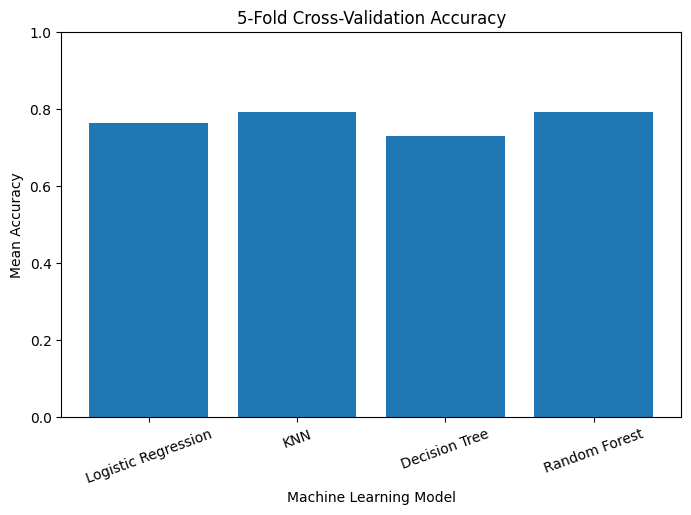

In [78]:
# Creating the CV results table

cv_results_df = pd.DataFrame(cv_results)

cv_results_df
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    cv_results_df["Model"],
    cv_results_df["CV Mean Accuracy"]
)

plt.title("5-Fold Cross-Validation Accuracy")
plt.xlabel("Machine Learning Model")
plt.ylabel("Mean Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)

plt.show()

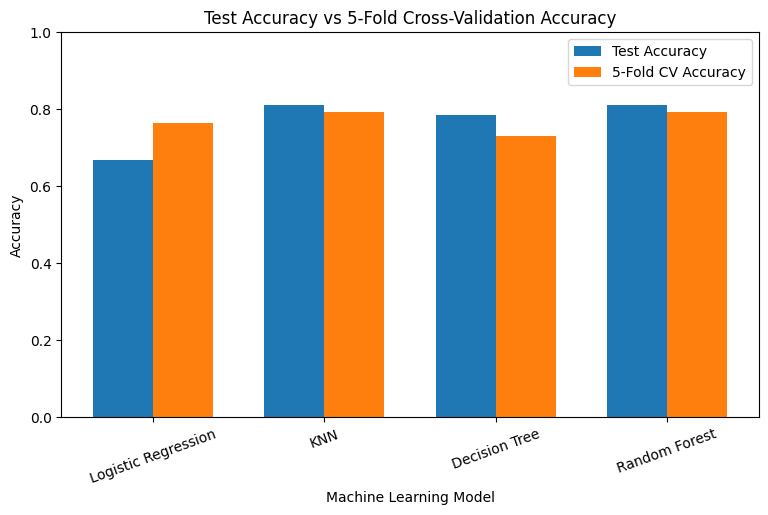

In [ ]:
# Test Accuracy vs 5-Fold Cross-Validation Accuracy

comparison_df = results_df[["Model", "Accuracy"]].copy()

comparison_df = comparison_df.rename(
    columns={"Accuracy": "Test Accuracy"}
)

comparison_df["CV Accuracy"] = cv_results_df["CV Mean Accuracy"]

comparison_df
import numpy as np
import matplotlib.pyplot as plt

x_pos = np.arange(len(comparison_df))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x_pos - width / 2,
    comparison_df["Test Accuracy"],
    width,
    label="Test Accuracy"
)

plt.bar(
    x_pos + width / 2,
    comparison_df["CV Accuracy"],
    width,
    label="5-Fold CV Accuracy"
)

plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")
plt.title("Test Accuracy vs 5-Fold Cross-Validation Accuracy")

plt.xticks(
    x_pos,
    comparison_df["Model"],
    rotation=20
)

plt.ylim(0, 1)
plt.legend()

plt.show()


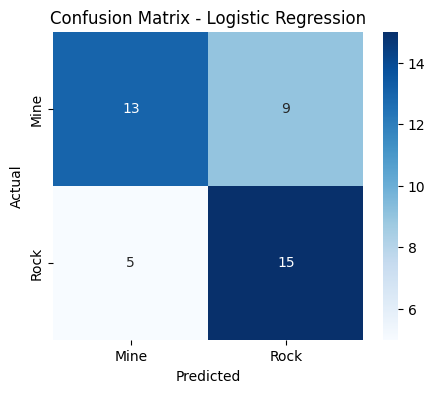

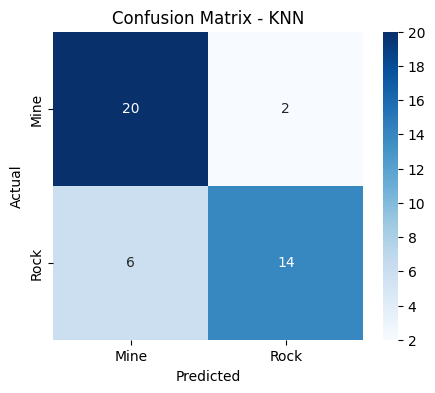

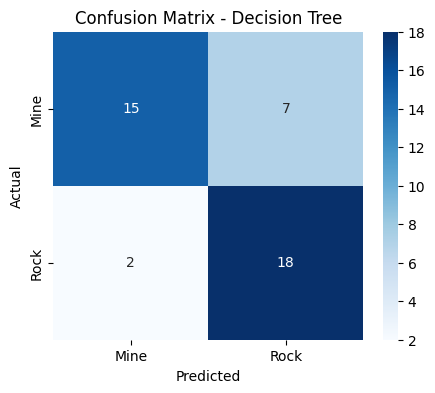

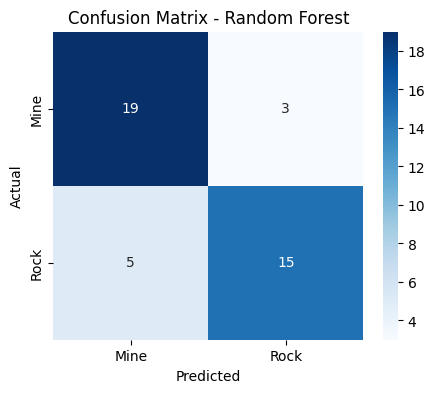

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

for name, model in models.items():

    y_pred = model.predict(x_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["M", "R"]
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Mine", "Rock"],
        yticklabels=["Mine", "Rock"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.show()

In [ ]:

final_comparison = results_df.merge(
    cv_results_df,
    on="Model"
)

final_comparison

,Model,Accuracy,Precision,Recall,F1 Score,CV Mean Accuracy,CV Standard Deviation
0,Logistic Regression,0.666667,0.722222,0.590909,0.650000,0.764692,0.036879
1,KNN,0.809524,0.769231,0.909091,0.833333,0.793031,0.045330
2,Decision Tree,0.785714,0.882353,0.681818,0.769231,0.730778,0.047093
3,Random Forest,0.809524,0.791667,0.863636,0.826087,0.793496,0.037883


In [ ]:
from sklearn.ensemble import RandomForestClassifier

final_model = RandomForestClassifier(
    n_estimators=100,
    random_state=1
)

final_model.fit(x, y)

print("Final Random Forest model trained successfully!")

Final Random Forest model trained successfully!


In [ ]:
import numpy as np

def predict_sonar(values):
    values = np.array(values).reshape(1, -1)

    prediction = final_model.predict(values)[0]
    probabilities = final_model.predict_proba(values)[0]

    print("Prediction:", prediction)
    print("Mine probability:", round(probabilities[0] * 100, 2), "%")
    print("Rock probability:", round(probabilities[1] * 100, 2), "%")

In [ ]:
sample = x.iloc[0].values
actual = y.iloc[0]

print("Actual:", actual)

predict_sonar(sample)


Actual: R
Prediction: R
Mine probability: 18.0 %
Rock probability: 82.0 %


In [ ]:
def user_prediction():
    print("Enter 60 sonar values separated by commas:")

    user_input = input()

    values = [float(v.strip()) for v in user_input.split(",")]

    if len(values) != 60:
        print("Error: Please enter exactly 60 values.")
        return

    values = np.array(values).reshape(1, -1)

    prediction = final_model.predict(values)[0]
    probabilities = final_model.predict_proba(values)[0]

    if prediction == "M":
        print("\nPrediction: MINE")
    else:
        print("\nPrediction: ROCK")

    print("Mine probability:", round(probabilities[0] * 100, 2), "%")
    print("Rock probability:", round(probabilities[1] * 100, 2), "%")

In [ ]:
# Take a real sample from the dataset
test_sample = x.iloc[10].values
actual_label = y.iloc[10]

print("Actual label:", actual_label)

# Convert sample to comma-separated input
sample_input = ",".join(map(str, test_sample))

# Simulate user input
values = [float(v.strip()) for v in sample_input.split(",")]

values = np.array(values).reshape(1, -1)

prediction = final_model.predict(values)[0]
probabilities = final_model.predict_proba(values)[0]

print("Predicted label:", prediction)
print("Mine probability:", round(probabilities[0] * 100, 2), "%")
print("Rock probability:", round(probabilities[1] * 100, 2), "%")

Actual label: R
Predicted label: R
Mine probability: 1.0 %
Rock probability: 99.0 %


In [ ]:
import joblib

joblib.dump(final_model, "sonar_random_forest.pkl")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
def interactive_prediction():
    print("===================================")
    print("     SONAR ROCK / MINE PREDICTOR")
    print("===================================")
    print("\nEnter the 60 sonar values separated by commas:\n")

    user_input = input()

    try:
        values = [float(v.strip()) for v in user_input.split(",")]
    except ValueError:
        print("\nError: Please enter only numeric values.")
        return

    if len(values) != 60:
        print(f"\nError: Expected 60 values, but received {len(values)}.")
        return

    values = np.array(values).reshape(1, -1)

    prediction = final_model.predict(values)[0]
    probabilities = final_model.predict_proba(values)[0]

    mine_probability = probabilities[list(final_model.classes_).index("M")]
    rock_probability = probabilities[list(final_model.classes_).index("R")]

    print("\n===================================")

    if prediction == "M":
        print("Prediction: MINE")
    else:
        print("Prediction: ROCK")

    print("Mine Probability:", round(mine_probability * 100, 2), "%")
    print("Rock Probability:", round(rock_probability * 100, 2), "%")

    print("===================================")

In [ ]:
# Use a real dataset sample
sample = x.iloc[20].values
actual = y.iloc[20]

print("Actual label:", actual)

# Convert the sample into the same comma-separated format
sample_input = ",".join(map(str, sample))

# Temporarily replace input() so the interactive function
# receives our real sample
import builtins

original_input = builtins.input
builtins.input = lambda: sample_input

interactive_prediction()

builtins.input = original_input

Actual label: R
     SONAR ROCK / MINE PREDICTOR

Enter the 60 sonar values separated by commas:


Prediction: ROCK
Mine Probability: 22.0 %
Rock Probability: 78.0 %
